Files Downloaded:   0%|          | 0/65 [00:00<?, ?file/s]

sci_xrsf-l2-avg1m_g10_d20061207_v1-0-0.nc:   0%|          | 0.00/51.0k [00:00<?, ?B/s]

sci_xrsf-l2-avg1m_g10_d20061209_v1-0-0.nc:   0%|          | 0.00/49.5k [00:00<?, ?B/s]

sci_xrsf-l2-avg1m_g10_d20061205_v1-0-0.nc:   0%|          | 0.00/50.9k [00:00<?, ?B/s]

sci_xrsf-l2-avg1m_g10_d20061206_v1-0-0.nc:   0%|          | 0.00/46.5k [00:00<?, ?B/s]

sci_xrsf-l2-avg1m_g10_d20061208_v1-0-0.nc:   0%|          | 0.00/49.4k [00:00<?, ?B/s]

... (57 outputs left out)

sci_xrsf-l2-avg1m_g12_d20061215_v1-0-0.nc:   0%|          | 0.00/59.6k [00:00<?, ?B/s]

sci_xrsf-l2-avg1m_g12_d20061216_v1-0-0.nc:   0%|          | 0.00/59.3k [00:00<?, ?B/s]

sci_xrsf-l2-avg1m_g12_d20061217_v1-0-0.nc:   0%|          | 0.00/59.3k [00:00<?, ?B/s]

FLARES:
    event_starttime          event_peaktime          event_endtime      fl_goescls ar_noaanum
----------------------- ----------------------- ----------------------- ---------- ----------
2006-12-05 10:18:00.000 2006-12-05 10:35:00.000 2006-12-05 10:45:00.000       X9.0      10930
2006-12-06 18:29:00.000 2006-12-06 18:47:00.000 2006-12-06 19:00:00.000       X6.5      10930
2006-12-13 02:14:00.000 2006-12-13 02:40:00.000 2006-12-13 02:57:00.000       X3.4      10930
2006-12-14 21:07:00.000 2006-12-14 22:15:00.000 2006-12-14 22:26:00.000       X1.5      10930
n_flares= 4


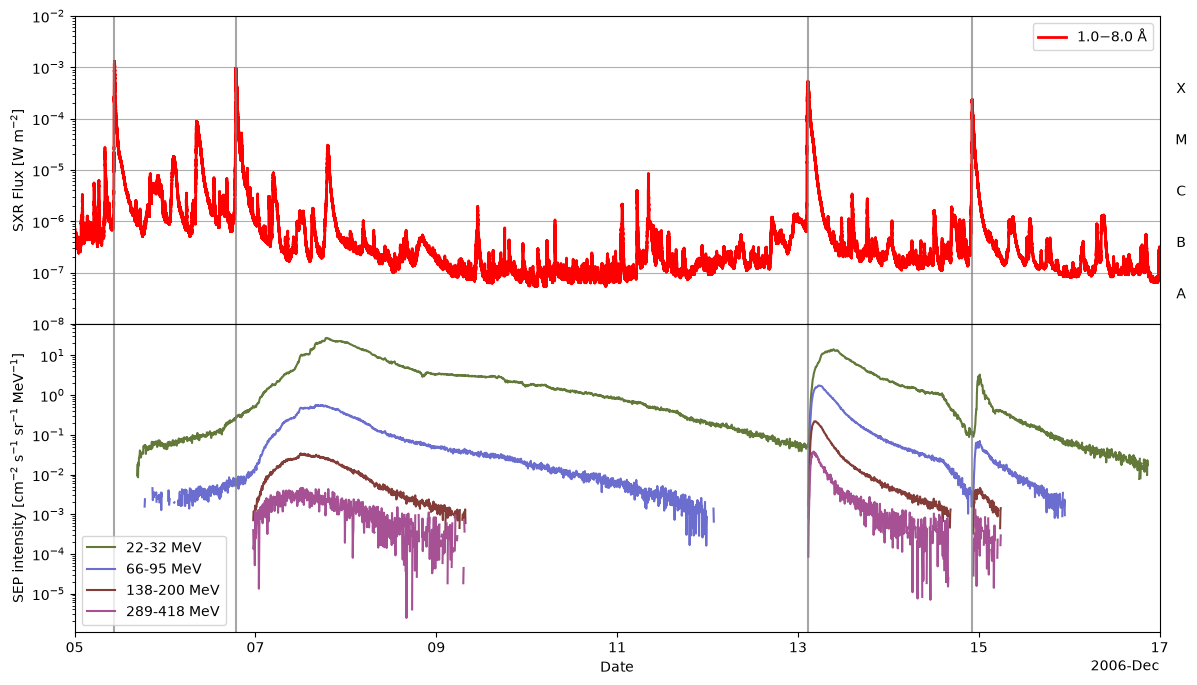

In [1]:
# PLOTS for SUPERACTIVE AR 10930 - December 2006

# make plot of GOES SXR time series data using sunpy

import matplotlib.pyplot as plt
import matplotlib as mpl

import numpy as np
import datetime

import pandas as pd

import sunpy.timeseries
import sunpy.data.sample

from sunpy.net import Fido
from sunpy.net import attrs as a

from sunpy.time import TimeRange, parse_time

from sunpy.util.metadata import MetaDict

                               # Making a plot of GOES SXR data with times of flares indicated by vertical lines

tr = a.Time('2006-12-05 00:00', '2006-12-17 00:00')   # set time range
#tr = a.Time('1989-10-19 00:00', '1989-10-31 00:00')   # set time range

goes = Fido.search(tr, a.Instrument.xrs) # a.goes.SatelliteNumber(15) & a.Resolution("avg1m")
# print('GOES files:',goes)

goes_files = Fido.fetch(goes)

                                               # Using these new files you get a list of timeseries
list_of_goes_ts = sunpy.timeseries.TimeSeries(goes_files, source='XRS')

combined_goes_ts = sunpy.timeseries.TimeSeries(goes_files, source='XRS', concatenate=True)                                                                          

event_type = "FL"    # define event type as a flare (“FL”)
                     # retrieve >X1.0 flares
flare_results = Fido.search(tr, a.hek.EventType(event_type), a.hek.FL.GOESCls > "X1.0", a.hek.OBS.Observatory == "GOES")

hek_results = flare_results['hek']
flares_hek = hek_results[0]

filtered_results = hek_results["event_starttime", "event_peaktime",
                               "event_endtime", "fl_goescls", "ar_noaanum"]
print('FLARES:') 
print(filtered_results)
print('n_flares=',len(filtered_results))
                                           
#  PLOT OF SEP data - using text file produced from SEPEM website of specific GOES channels (SEPEM H RDS v3-1-beta)
#
# File contains:
# Epoch, Interval length (s), Proton Fluxes in cm^-2 s^-1 sr^-1 MeV^-1 in channels: 22-32 MeV, 66-95 MeV, 138-200 MeV, 289-418 MeV

                                            # ---NOW READ IN SEP DATA---

sep_input_file='sepem_v3_ar10930.txt'     # file with SEP data from SEPEM

sep_data = pd.read_csv(sep_input_file)    #  read csv file into pandas dataframe: sep_data

sep_data=sep_data.replace(0, np.nan)

sep_data.date=pd.to_datetime(sep_data.date)


fig, (ax0, ax1) = plt.subplots(nrows=2, ncols=1,sharex=True, figsize=(14,8))
fig.subplots_adjust(hspace=0)

plot_settings = {"xrsa": ["blue", r"0.5$-$4.0 $\mathrm{\AA}$"], "xrsb": ["green", r"1.0$-$8.0 $\mathrm{\AA}$"]}
combined_goes_ts.plot(axes=ax0,columns=["xrsb"])      # goes.plot(axes=ax);  xrsb is the 1-8 A channel

for flare in filtered_results:                          # plot vertical line at peak time of flare
   ax0.axvline(parse_time(flare['event_peaktime']).datetime, color='grey', alpha=0.7, label=flare['fl_goescls'])   

#for flare in filtered_results:                 
#   ax.axvspan(                                               # plot a vertical coloured strip betwen start and end
#       parse_time(flare['event_starttime']).datetime,
#       parse_time(flare['event_endtime']).datetime,
#       alpha=0.2, label=flare['fl_goescls']
#   )

#ax0.legend(loc='upper right')                                   # uncomment to display legend
#ax0.set_title('AR 10930, December 2006', fontsize='large')
ax0.set_ylabel(r'SXR Flux [W m$^{-2}$]')
#ax0.set_color("brown")   trying to change colour of the line
#ax0.gca().get_lines()[0].set_color("black")
#ax0.annotate('E80', xy=(datetime(2006,12,6), 7e-3))

ax0.set_ylim(1e-8, 1e-2)
ax0.set_xlim(tr.start.to_datetime(), tr.end.to_datetime())

ch_labels=['22-32 MeV', '66-95 MeV','138-200 MeV','289-418 MeV']

cmap=mpl.colormaps['tab20b']    # choose a colour map
colors=cmap(np.linspace(0,1,40))   # extract 40 colours at regular intervals

ax1.plot(sep_data.date,sep_data.f1, color=colors[8])
ax1.plot(sep_data.date,sep_data.f2, color=colors[5])
ax1.plot(sep_data.date,sep_data.f3, color=colors[24])
ax1.plot(sep_data.date,sep_data.f4, color=colors[34])
ax1.legend(labels=ch_labels, loc='lower left')

ax1.set_yscale('log')
ax1.set_xlabel('Date')
ax1.set_ylabel(r'SEP intensity [cm$^{-2}$ s$^{-1}$ sr$^{-1}$ MeV$^{-1}$]')

for flare in filtered_results:                          # plot vertical line at peak time of flare
   ax1.axvline(parse_time(flare['event_peaktime']).datetime, color='grey', alpha=0.7) 

plt.savefig('AR10930_flare_sep.jpg', dpi=400)
plt.show()
